# Trabajo Final Integrador — Clasificación de ecografías mamarias (BUSI)
**Grupo 38** · Diplomatura en Ciencia de Datos y Análisis Avanzado · UTN BA

**Criterio rector:** el error que NO queremos es el *falso negativo* de la clase **maligno**
(un tumor maligno clasificado como normal o benigno). Por eso:
1. Todos los modelos se comparan con el mismo criterio: **Recall de maligno ≥ 90 %**, ajustando el umbral de decisión **en validación**.
2. Entre los que cumplen, se prefiere el de mayor **Precision de maligno** (menos falsos positivos). Un modelo que dice "maligno" para todo tiene Recall 100 % y no sirve: por eso se incluye como referencia.
3. El conjunto de **test se usa una sola vez**, al final, y nunca para elegir modelo ni umbral.

**Estructura (CRISP-DM):** 1 Comprensión del negocio y de los datos (EDA) · 2 Preparación (duplicados, máscaras, padding, split) ·
3 Modelado (RF+GLCM, CNN desde cero, ResNet50) · 4 Evaluación y selección · 5 Interpretabilidad (Grad-CAM) · 6 Valor de negocio.

Ejecución local: `pip install -r requirements.txt` y luego correr todas las celdas (ver README). Para una corrida de humo rápida: variable de entorno `MODO_PRUEBA=1`.

In [1]:
import os, sys, json, glob, random, warnings, importlib.util, subprocess
warnings.filterwarnings("ignore", category=FutureWarning)

for modulo, paquete in [("imagehash", "imagehash"), ("kagglehub", "kagglehub"),
                        ("skimage", "scikit-image"), ("cv2", "opencv-python-headless")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import numpy as np
import pandas as pd
import cv2
import imagehash
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, f1_score, accuracy_score,
                             roc_auc_score, roc_curve, classification_report)
from sklearn.utils.class_weight import compute_class_weight
from skimage.feature import graycomatrix, graycoprops

SEED = 42
random.seed(SEED); np.random.seed(SEED)

MODO_PRUEBA = os.environ.get("MODO_PRUEBA", "0") == "1"   # corrida de humo (no usar para resultados)
IMG_SIZE = 224
CLASSES = ["normal", "benign", "malignant"]               # ORDEN FIJO en todo el notebook
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
MAL = CLS2IDX["malignant"]
NOMBRES_ES = {"normal": "Normal", "benign": "Benigno", "malignant": "Maligno"}

RECALL_OBJETIVO = 0.90     # umbral de negocio (no negociable)
PRECISION_PISO = 0.75      # piso orientativo de Precision en maligno (pre-entrega)
# Referencia externa: Azarpey, N. (2023). Sensitivity and specificity of ultrasound and mammography for detection of
# breast malignancy: a systematic review and meta-analysis. Oncology and Radiotherapy, 17(9), 333-339.
# Meta-análisis de 28 estudios (mujeres con sospecha de cáncer de mama): ecografía, sensibilidad combinada 87 % (IC95 80-92 %),
# especificidad combinada 75 % (IC95 61-84 %). Es un promedio de estudios (distintos lectores y equipos), no un radiólogo individual.
SENS_LIT, SENS_LIT_IC = 0.87, (0.80, 0.92)
ESPEC_LIT, ESPEC_LIT_IC = 0.75, (0.61, 0.84)
SENS_PISO = SENS_LIT_IC[0]  # 0,80: piso conservador (límite inferior del IC95 de la referencia)
PHASH_DIST = 4             # distancia de Hamming máxima para considerar "casi duplicada"
CV_PROFUNDO = False        # True = CV k=5 también para las redes (lento)

EPOCHS_CNN, EPOCHS_HEAD, EPOCHS_FT = (1, 1, 1) if MODO_PRUEBA else (30, 20, 20)
PESOS_RESNET = None if MODO_PRUEBA else "imagenet"
FIG_DIR = "figuras"; os.makedirs(FIG_DIR, exist_ok=True)

## 1. Datos y EDA

In [2]:
def localizar_dataset():
    ruta = os.environ.get("BUSI_PATH")
    if not ruta:
        import kagglehub
        ruta = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")
    for root, dirs, _ in os.walk(ruta):
        if set(CLASSES).issubset(set(dirs)):
            return root
    raise FileNotFoundError("No se encontró la carpeta con normal/benign/malignant")

BASE = localizar_dataset()

filas = []
for c in CLASSES:
    d = os.path.join(BASE, c)
    for f in sorted(os.listdir(d)):
        if f.lower().endswith(".png") and "_mask" not in f:
            masks = sorted(glob.glob(os.path.join(d, glob.escape(f[:-4]) + "_mask*.png")))
            filas.append(dict(image_path=os.path.join(d, f), label=c, mask_paths=masks))
df = pd.DataFrame(filas)

def meta(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return g.shape[0], g.shape[1], float(g.mean()), float(g.std())

df[["height_px", "width_px", "mean_intensity", "std_intensity"]] = [meta(p) for p in df.image_path]
df["aspect_ratio"] = df.width_px / df.height_px

def tiene_lesion(mask_paths):
    return int(any((cv2.imread(m, cv2.IMREAD_GRAYSCALE) > 0).any() for m in mask_paths))

# has_mask = 1 solo si existe al menos una máscara con píxeles de lesión; "normal" => 0 (ajuste documentado en Metodología)
df["has_mask"] = df.mask_paths.apply(tiene_lesion)
df["n_masks"] = df.mask_paths.apply(len)
df["has_multiple_masks"] = (df.n_masks > 1).astype(int)

print(f"Imágenes encontradas: {len(df)}")
print((df.label.value_counts(normalize=True).reindex(CLASSES) * 100).round(1).astype(str) + " %")
print(df.label.value_counts().reindex(CLASSES).to_string())
print("\nValores nulos por columna (excluye mask_paths):\n", df.drop(columns="mask_paths").isna().sum().to_string())
print("\nResumen numérico:\n", df[["height_px", "width_px", "aspect_ratio", "mean_intensity", "std_intensity"]].describe().round(2).to_string())
print("\nhas_mask por clase:\n", df.groupby("label").has_mask.mean().reindex(CLASSES).round(2).to_string())
print("Imágenes con más de una máscara:", int(df.has_multiple_masks.sum()))

100%|██████████| 195M/195M [00:00<00:00, 211MB/s]

Extracting files...


Imágenes encontradas: 780
label
normal       17.1 %
benign       56.0 %
malignant    26.9 %
Name: proportion, dtype: object
label
normal       133
benign       437
malignant    210

Valores nulos por columna (excluye mask_paths):
 image_path            0
label                 0
height_px             0
width_px              0
mean_intensity        0
std_intensity         0
aspect_ratio          0
has_mask              0
n_masks               0
has_multiple_masks    0

Resumen numérico:
        height_px  width_px  aspect_ratio  mean_intensity  std_intensity
count     780.00    780.00        780.00          780.00         780.00
mean      501.45    615.68          1.23           83.63          51.53
std        76.69    122.06          0.17           21.35           9.16
min       310.00    190.00          0.57           29.91          27.53
25%       465.00    554.00          1.17           68.08          45.13
50%       474.00    564.00          1.20           83.47          51.99
75%  

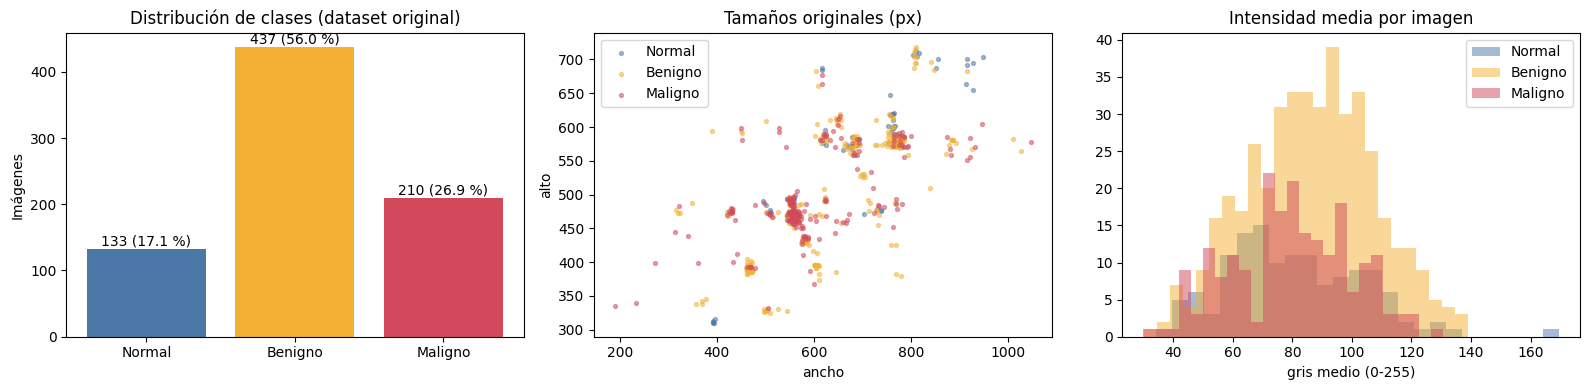

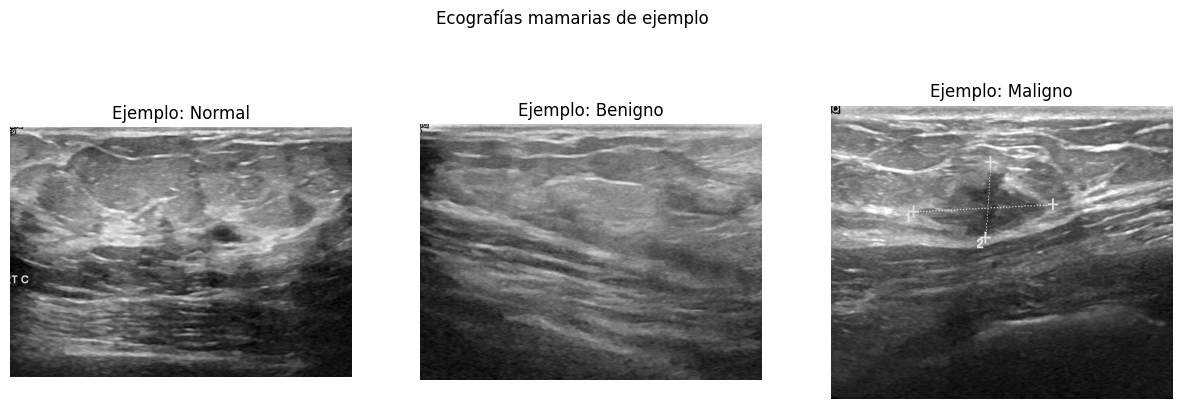

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
conteo = df.label.value_counts().reindex(CLASSES)
ax[0].bar([NOMBRES_ES[c] for c in CLASSES], conteo.values, color=["#4c78a8", "#f2b134", "#d1495b"])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v + 5, f"{v} ({v / len(df) * 100:.1f} %)", ha="center")
ax[0].set_title("Distribución de clases (dataset original)"); ax[0].set_ylabel("Imágenes")
for c, col in zip(CLASSES, ["#4c78a8", "#f2b134", "#d1495b"]):
    ax[1].scatter(df[df.label == c].width_px, df[df.label == c].height_px, s=8, alpha=.5, color=col, label=NOMBRES_ES[c])
ax[1].set_title("Tamaños originales (px)"); ax[1].set_xlabel("ancho"); ax[1].set_ylabel("alto"); ax[1].legend()
for c, col in zip(CLASSES, ["#4c78a8", "#f2b134", "#d1495b"]):
    ax[2].hist(df[df.label == c].mean_intensity, bins=25, alpha=.5, color=col, label=NOMBRES_ES[c])
ax[2].set_title("Intensidad media por imagen"); ax[2].set_xlabel("gris medio (0-255)"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_distribuciones.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i, c in enumerate(CLASSES):
    fila = df[df.label == c].sample(1, random_state=SEED).iloc[0]
    ax[i].imshow(cv2.imread(fila.image_path, cv2.IMREAD_GRAYSCALE), cmap="gray")
    ax[i].set_title(f"Ejemplo: {NOMBRES_ES[c]}"); ax[i].axis("off")
plt.suptitle("Ecografías mamarias de ejemplo"); plt.savefig(f"{FIG_DIR}/eda_ejemplos.png", dpi=150); plt.show()

## 2. Preparación de datos
**Duplicados:** el dataset no trae ID de paciente. Se usa *perceptual hashing* (pHash) para detectar imágenes idénticas o casi idénticas **antes** de particionar.
- Grupo de casi-duplicados con la **misma** etiqueta → se conserva una sola imagen.
- Grupo con etiquetas **contradictorias** → se eliminan todas (ruido de etiquetado).

**Limitación que no se puede resolver con los datos:** imágenes *distintas* de una misma paciente (hay ~600 pacientes y 780 imágenes) no se detectan con hashing. Puede haber fuga de información entre train y test; se declara como limitación.

In [4]:
hashes = [imagehash.phash(Image.open(p).convert("L")) for p in df.image_path]
n = len(df)
parent = list(range(n))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i in range(n):
    for j in range(i + 1, n):
        if hashes[i] - hashes[j] <= PHASH_DIST:
            parent[find(j)] = find(i)
df["cluster"] = [find(i) for i in range(n)]
g = df.groupby("cluster").label
tam, nlab = g.transform("size"), g.transform("nunique")
df["dup_conflicto"] = (tam > 1) & (nlab > 1)
df["dup_redundante"] = (tam > 1) & (nlab == 1) & df.duplicated("cluster", keep="first")
print(f"Grupos de casi-duplicados: {(df.groupby('cluster').size() > 1).sum()}")
print(f"Imágenes redundantes (misma etiqueta) a eliminar: {int(df.dup_redundante.sum())}")
print(f"Imágenes en grupos con etiquetas contradictorias a eliminar: {int(df.dup_conflicto.sum())}")
n_antes = len(df)
df = df[~df.dup_conflicto & ~df.dup_redundante].reset_index(drop=True)
print(f"Dataset: {n_antes} -> {len(df)} imágenes")
print(df.label.value_counts().reindex(CLASSES).to_string())

Grupos de casi-duplicados: 124
Imágenes redundantes (misma etiqueta) a eliminar: 143
Imágenes en grupos con etiquetas contradictorias a eliminar: 18
Dataset: 780 -> 619 imágenes
label
normal        94
benign       332
malignant    193


In [5]:
def letterbox(img, size=IMG_SIZE, interp=cv2.INTER_AREA):
    """Redimensiona conservando aspect ratio y rellena con negro hasta size x size."""
    h, w = img.shape[:2]
    s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    r = cv2.resize(img, (nw, nh), interpolation=interp)
    out = np.zeros((size, size), dtype=img.dtype)
    y0, x0 = (size - nh) // 2, (size - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = r
    return out

def cargar_mascara(row):
    h, w = int(row.height_px), int(row.width_px)
    m = np.zeros((h, w), dtype=np.uint8)
    for p in row.mask_paths:
        mm = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        if mm.shape != (h, w):
            mm = cv2.resize(mm, (w, h), interpolation=cv2.INTER_NEAREST)
        m |= (mm > 0).astype(np.uint8)
    return letterbox(m, interp=cv2.INTER_NEAREST)

X = np.stack([letterbox(cv2.imread(p, cv2.IMREAD_GRAYSCALE)) for p in df.image_path])          # (N,224,224) uint8
M = np.stack([cargar_mascara(r) for r in df.itertuples()])                                      # (N,224,224) {0,1}
X3 = np.repeat(X[..., None], 3, axis=-1)                                                        # (N,224,224,3)
y = df.label.map(CLS2IDX).values

idx = np.arange(len(df))
idx_tr, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)
for nombre, ii in [("train", idx_tr), ("val", idx_va), ("test", idx_te)]:
    print(f"{nombre:5s} n={len(ii):4d}  " + "  ".join(f"{NOMBRES_ES[c]}={int((y[ii] == CLS2IDX[c]).sum())}" for c in CLASSES))
y_tr, y_va, y_te = y[idx_tr], y[idx_va], y[idx_te]

train n= 433  Normal=66  Benigno=232  Maligno=135
val   n=  93  Normal=14  Benigno=50  Maligno=29
test  n=  93  Normal=14  Benigno=50  Maligno=29


## 3. Funciones de evaluación (comunes a todos los modelos)
Se fijan **antes** de entrenar. Predicción con umbral: se predice *maligno* si `P(maligno) ≥ t`; si no, la mayor probabilidad entre las otras dos clases.
El IC95 de Recall usa el intervalo de Wilson: con pocos casos malignos en test la incertidumbre es grande y hay que reportarla.

In [6]:
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

def norm(p):
    p = np.asarray(p, dtype="float64")
    return p / p.sum(1, keepdims=True)

def pred_umbral(proba, t=None):
    pred = proba.argmax(1)
    if t is None: return pred
    otras = [i for i in range(proba.shape[1]) if i != MAL]
    alt = np.array(otras)[proba[:, otras].argmax(1)]
    return np.where(proba[:, MAL] >= t, MAL, alt)

def rec_prec(yv, pred):
    tp = int(((pred == MAL) & (yv == MAL)).sum()); fn = int(((pred != MAL) & (yv == MAL)).sum())
    fp = int(((pred == MAL) & (yv != MAL)).sum())
    return (tp / (tp + fn) if tp + fn else np.nan), (tp / (tp + fp) if tp + fp else 0.0)

def elegir_umbral(yv, proba):
    """Mayor Precision de maligno sujeta a Recall >= objetivo (en VALIDACIÓN). Si ninguno cumple, el de mayor Recall."""
    filas = []
    for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
        r, p = rec_prec(yv, pred_umbral(proba, t)); filas.append((t, r, p))
    ok = [f for f in filas if f[1] >= RECALL_OBJETIVO]
    if ok: return float(max(ok, key=lambda f: (f[2], f[0]))[0]), True
    return float(max(filas, key=lambda f: (f[1], f[2]))[0]), False

def metricas(yv, proba, t=None):
    proba = norm(proba); pred = pred_umbral(proba, t)
    rec, prec = rec_prec(yv, pred)
    k, nn = int(((pred == MAL) & (yv == MAL)).sum()), int((yv == MAL).sum())
    lo, hi = wilson(k, nn)
    cm = confusion_matrix(yv, pred, labels=[0, 1, 2])
    try: auc = roc_auc_score(yv, proba, multi_class="ovr", average="macro", labels=[0, 1, 2])
    except ValueError: auc = np.nan
    return dict(umbral=t, recall_mal=rec, ic95_lo=lo, ic95_hi=hi, precision_mal=prec,
                f1_mal=(2 * prec * rec / (prec + rec)) if prec + rec > 0 else 0.0,
                f1_macro=f1_score(yv, pred, average="macro", labels=[0, 1, 2], zero_division=0),
                auc_ovr=auc, auc_mal=roc_auc_score((yv == MAL).astype(int), proba[:, MAL]),
                accuracy=accuracy_score(yv, pred),
                fn_mal_a_normal=int(cm[MAL, 0]), fn_mal_a_benigno=int(cm[MAL, 1]),
                n_mal=nn, cm=cm.tolist())

resultados = {}   # nombre -> dict(proba_val, proba_test, umbral, cumple, m_val, m_test)
def registrar(nombre, p_val, p_test):
    p_val, p_test = norm(p_val), norm(p_test)
    t, cumple = elegir_umbral(y_va, p_val)
    resultados[nombre] = dict(proba_val=p_val, proba_test=p_test, umbral=t, cumple_en_val=cumple,
                              m_val=metricas(y_va, p_val, t), m_test=metricas(y_te, p_test, t),
                              m_val_argmax=metricas(y_va, p_val, None), m_test_argmax=metricas(y_te, p_test, None))
    r = resultados[nombre]
    print(f"[{nombre}] umbral(val)={t:.2f} | VAL recall={r['m_val']['recall_mal']:.3f} prec={r['m_val']['precision_mal']:.3f}"
          f" | (argmax: recall val={r['m_val_argmax']['recall_mal']:.3f})")

## 4. Modelado
### Modelo 1 — Baseline clásico: textura GLCM + Random Forest

In [7]:
def features_glcm(imgs):
    out = []
    for im in imgs:
        q = (im // 4).astype(np.uint8)                      # 64 niveles de gris
        glcm = graycomatrix(q, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                            levels=64, symmetric=True, normed=True)
        f = []
        for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
            f.extend(graycoprops(glcm, prop).mean(axis=1))   # promedio sobre ángulos, uno por distancia
        f.extend([im.mean(), im.std()])
        out.append(f)
    return np.array(out)

print("Extrayendo características GLCM...")
F = features_glcm(X)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)

# Validación cruzada estratificada k=5 SOLO sobre train (estabilidad del baseline)
cv_rec = []
for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(F[idx_tr], y_tr):
    m = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(F[idx_tr][a], y_tr[a])
    cv_rec.append(rec_prec(y_tr[b], m.predict(F[idx_tr][b]))[0])
print(f"CV k=5 (train) Recall maligno RF [argmax]: {np.nanmean(cv_rec):.3f} ± {np.nanstd(cv_rec):.3f}")

rf.fit(F[idx_tr], y_tr)
registrar("RF + GLCM", rf.predict_proba(F[idx_va]), rf.predict_proba(F[idx_te]))

Extrayendo características GLCM...
CV k=5 (train) Recall maligno RF [argmax]: 0.556 ± 0.110
[RF + GLCM] umbral(val)=0.10 | VAL recall=0.931 prec=0.403 | (argmax: recall val=0.448)


### Modelo 2 y 3 — Redes convolucionales (Keras)
- **CNN desde cero**: sin Transfer Learning y **sin Data Augmentation** (como en la pre-entrega), con class weights.
- **ResNet50 (Transfer Learning)**: pesos ImageNet, `preprocess_input` propio de ResNet (BGR − media), class weights, Data Augmentation **solo en entrenamiento**,
  2 etapas: (a) cabeza con base congelada; (b) fine-tuning del último bloque con LR bajo (BatchNorm congelada).
- Early stopping sobre la pérdida de **validación**. Semillas fijas.

In [8]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(SEED)

cw = compute_class_weight("balanced", classes=np.arange(3), y=y_tr)
CW = {i: float(w) for i, w in enumerate(cw)}
print("class weights:", {NOMBRES_ES[CLASSES[i]]: round(w, 2) for i, w in CW.items()})

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]

def build_cnn():
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1. / 255)(inp)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, activation="relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x); x = layers.Dropout(0.5)(x)
    m = keras.Model(inp, layers.Dense(3, activation="softmax")(x), name="cnn_scratch")
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

class weights: {'Normal': 2.19, 'Benigno': 0.62, 'Maligno': 1.07}


In [9]:
cnn = build_cnn()
h_cnn = cnn.fit(X3[idx_tr], y_tr, validation_data=(X3[idx_va], y_va), epochs=EPOCHS_CNN,
                batch_size=32, class_weight=CW, callbacks=callbacks(), verbose=0)
print("épocas CNN:", len(h_cnn.history["loss"]))
registrar("CNN desde cero", cnn.predict(X3[idx_va], verbose=0), cnn.predict(X3[idx_te], verbose=0))

épocas CNN: 6
[CNN desde cero] umbral(val)=0.31 | VAL recall=1.000 prec=0.312 | (argmax: recall val=0.000)


In [10]:
MEDIA_BGR = np.array([103.939, 116.779, 123.68], dtype="float32")
def preproc_resnet(t):                       # equivalente a resnet50.preprocess_input (RGB->BGR y resta de media)
    return tf.reverse(t, axis=[-1]) - tf.constant(MEDIA_BGR)

aug = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(15 / 360), layers.RandomZoom(0.1)], name="augment")
base = keras.applications.ResNet50(weights=PESOS_RESNET, include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
gap, d1, drop, salida = layers.GlobalAveragePooling2D(), layers.Dense(128, activation="relu"), layers.Dropout(0.5), layers.Dense(3, activation="softmax")

inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = layers.Lambda(lambda t: tf.cast(t, tf.float32))(inp)
x = aug(x)                                    # activa solo con training=True
x = layers.Lambda(preproc_resnet)(x)
x = base(x, training=False)
x = drop(d1(gap(x)))
resnet = keras.Model(inp, salida(x), name="resnet50_tl")

# Etapa (a): cabeza
resnet.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
resnet.fit(X3[idx_tr], y_tr, validation_data=(X3[idx_va], y_va), epochs=EPOCHS_HEAD, batch_size=32,
           class_weight=CW, callbacks=callbacks(), verbose=0)
# Etapa (b): fine-tuning del último bloque
base.trainable = True
for capa in base.layers[:-30]: capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization): capa.trainable = False
resnet.compile(keras.optimizers.Adam(1e-5), "sparse_categorical_crossentropy", metrics=["accuracy"])
h_ft = resnet.fit(X3[idx_tr], y_tr, validation_data=(X3[idx_va], y_va), epochs=EPOCHS_FT, batch_size=32,
                  class_weight=CW, callbacks=callbacks(), verbose=0)
print("épocas fine-tuning:", len(h_ft.history["loss"]))
registrar("ResNet50 (TL)", resnet.predict(X3[idx_va], verbose=0), resnet.predict(X3[idx_te], verbose=0))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
épocas fine-tuning: 15
[ResNet50 (TL)] umbral(val)=0.10 | VAL recall=0.931 prec=0.529 | (argmax: recall val=0.828)


In [11]:
if CV_PROFUNDO:
    cv_res = []
    for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X3[idx_tr], y_tr):
        m = build_cnn()
        m.fit(X3[idx_tr][a], y_tr[a], epochs=EPOCHS_CNN, batch_size=32, class_weight=CW, verbose=0)
        cv_res.append(rec_prec(y_tr[b], m.predict(X3[idx_tr][b], verbose=0).argmax(1))[0])
    print(f"CV k=5 CNN desde cero, Recall maligno [argmax]: {np.nanmean(cv_res):.3f} ± {np.nanstd(cv_res):.3f}")
else:
    print("CV profunda desactivada (CV_PROFUNDO=False): la CV k=5 se aplicó solo al Random Forest.")

CV profunda desactivada (CV_PROFUNDO=False): la CV k=5 se aplicó solo al Random Forest.


## 5. Evaluación y selección del modelo
Regla definida **antes** de mirar test:
1. Cada modelo ajusta su umbral en **validación** para lograr Recall de maligno ≥ 90 %.
2. Entre los que lo logran, gana el de mayor **Precision de maligno** en validación; se verifica además el piso de Precision ≥ 75 %.
3. Recién entonces se reporta test (una sola vez), con IC95 del Recall.

Referencias: **"Siempre maligno"** (Recall 100 % trivial; muestra por qué Recall solo no alcanza) y la **referencia de la literatura** (Azarpey, 2023: sensibilidad combinada de la ecografía 87 %, IC95 80-92 %; piso conservador 80 %).

In [12]:
def fila(nombre, r):
    v, t = r["m_val"], r["m_test"]
    return {"Modelo": nombre, "Umbral(val)": r["umbral"], "Cumple Recall≥90% (val)": r["cumple_en_val"],
            "Recall mal. VAL": v["recall_mal"], "Precision mal. VAL": v["precision_mal"],
            "Recall mal. TEST": t["recall_mal"], "IC95 Recall TEST": f"{t['ic95_lo']:.2f}-{t['ic95_hi']:.2f}",
            "Precision mal. TEST": t["precision_mal"], "F1 mal. TEST": t["f1_mal"], "F1-macro TEST": t["f1_macro"],
            "AUC-ROC OvR TEST": t["auc_ovr"], "AUC mal. TEST": t["auc_mal"],
            "FN mal→normal": t["fn_mal_a_normal"], "FN mal→benigno": t["fn_mal_a_benigno"], "Recall mal. TEST (argmax)": r["m_test_argmax"]["recall_mal"]}

tabla = pd.DataFrame([fila(n, r) for n, r in resultados.items()])
siempre = np.full(len(y_te), MAL); r_s, p_s = rec_prec(y_te, siempre)
print(f"Referencia 'Siempre maligno' (TEST): Recall={r_s:.2f}, Precision={p_s:.2f}  <- Recall 100% sin utilidad clínica")
print(f"Referencia de la literatura (Azarpey, 2023): sensibilidad ≈ {SENS_LIT:.0%} (IC95 {SENS_LIT_IC[0]:.0%}-{SENS_LIT_IC[1]:.0%}); piso conservador {SENS_PISO:.0%}\n")
pd.set_option("display.width", 250, "display.max_columns", 30)
print(tabla.round(3).to_string(index=False))

cands = [n for n, r in resultados.items() if r["m_val"]["recall_mal"] >= RECALL_OBJETIVO]
if cands:
    elegido = max(cands, key=lambda n: resultados[n]["m_val"]["precision_mal"])
    print(f"\nModelo elegido (regla en validación): {elegido}")
else:
    elegido = max(resultados, key=lambda n: resultados[n]["m_val"]["recall_mal"])
    print(f"\nNINGÚN modelo alcanzó Recall≥90% en validación. Mayor recall: {elegido}. NO se puede afirmar que se cumple el KPI.")
rE = resultados[elegido]
print(f"Piso de Precision ≥ {PRECISION_PISO:.0%} en validación: {'SÍ' if rE['m_val']['precision_mal'] >= PRECISION_PISO else 'NO'}")
print(f"TEST (una sola vez): Recall maligno={rE['m_test']['recall_mal']:.3f} (IC95 {rE['m_test']['ic95_lo']:.2f}-{rE['m_test']['ic95_hi']:.2f}, n={rE['m_test']['n_mal']}), "
      f"Precision={rE['m_test']['precision_mal']:.3f}")
print(f"¿IC95 inferior ≥ 90 %?: {'SÍ' if rE['m_test']['ic95_lo'] >= RECALL_OBJETIVO else 'NO (evidencia estadística limitada con tan pocos casos malignos)'}")
print(f"¿Supera la referencia de la literatura ({SENS_LIT:.0%}; piso {SENS_PISO:.0%})?: ", "SÍ (punto estimado)" if rE['m_test']['recall_mal'] > SENS_LIT else "NO",
      f"| IC95 inferior del modelo = {rE['m_test']['ic95_lo']:.2f} (si los intervalos se solapan, no se afirma superioridad estadística)")

Referencia 'Siempre maligno' (TEST): Recall=1.00, Precision=0.31  <- Recall 100% sin utilidad clínica
Referencia de la literatura (Azarpey, 2023): sensibilidad ≈ 87% (IC95 80%-92%); piso conservador 80%

        Modelo  Umbral(val)  Cumple Recall≥90% (val)  Recall mal. VAL  Precision mal. VAL  Recall mal. TEST IC95 Recall TEST  Precision mal. TEST  F1 mal. TEST  F1-macro TEST  AUC-ROC OvR TEST  AUC mal. TEST  FN mal→normal  FN mal→benigno  Recall mal. TEST (argmax)
     RF + GLCM         0.10                     True            0.931               0.403             0.862        0.69-0.95                0.347         0.495          0.279             0.695          0.782              0               4                      0.448
CNN desde cero         0.31                     True            1.000               0.312             1.000        0.88-1.00                0.312         0.475          0.158             0.542          0.573              0               0                      0.00

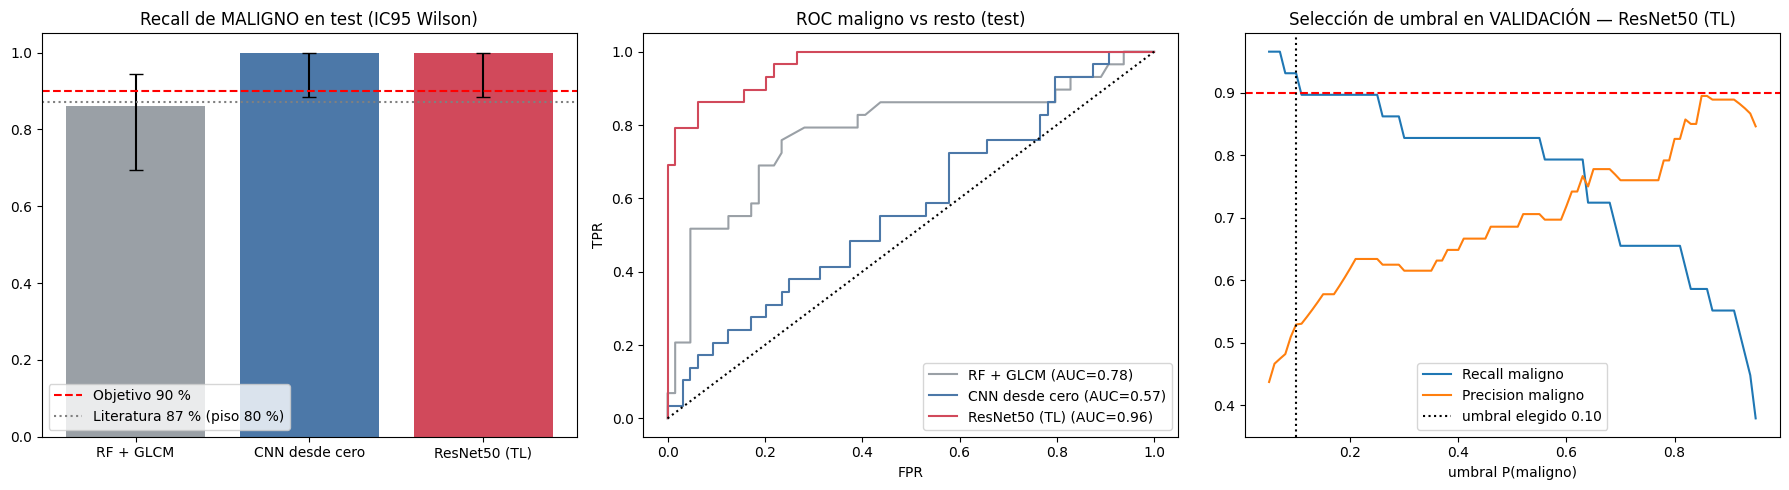

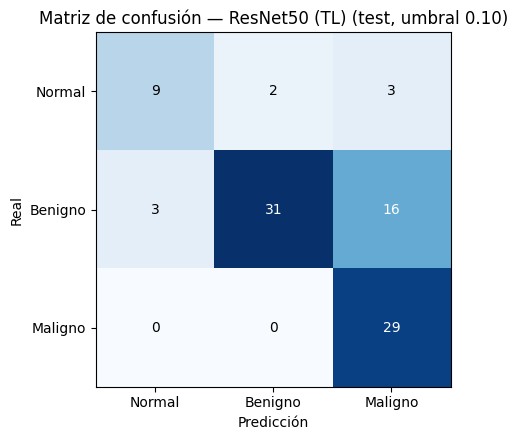

              precision    recall  f1-score   support

      Normal       0.75      0.64      0.69        14
     Benigno       0.94      0.62      0.75        50
     Maligno       0.60      1.00      0.75        29

    accuracy                           0.74        93
   macro avg       0.76      0.75      0.73        93
weighted avg       0.81      0.74      0.74        93



In [13]:
colores = {"RF + GLCM": "#9aa0a6", "CNN desde cero": "#4c78a8", "ResNet50 (TL)": "#d1495b"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
nombres = list(resultados)
rec = [resultados[n]["m_test"]["recall_mal"] for n in nombres]
err = np.clip(np.nan_to_num([[resultados[n]["m_test"]["recall_mal"] - resultados[n]["m_test"]["ic95_lo"] for n in nombres],
                             [resultados[n]["m_test"]["ic95_hi"] - resultados[n]["m_test"]["recall_mal"] for n in nombres]]), 0, None)
ax[0].bar(nombres, rec, yerr=err, capsize=5, color=[colores[n] for n in nombres])
ax[0].axhline(RECALL_OBJETIVO, color="r", ls="--", label="Objetivo 90 %")
ax[0].axhline(SENS_LIT, color="gray", ls=":", label="Literatura 87 % (piso 80 %)")
ax[0].set_ylim(0, 1.05); ax[0].set_title("Recall de MALIGNO en test (IC95 Wilson)"); ax[0].legend()
for n in nombres:
    fpr, tpr, _ = roc_curve((y_te == MAL).astype(int), resultados[n]["proba_test"][:, MAL])
    ax[1].plot(fpr, tpr, color=colores[n], label=f"{n} (AUC={resultados[n]['m_test']['auc_mal']:.2f})")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_title("ROC maligno vs resto (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
ts = np.round(np.arange(0.05, 0.96, 0.01), 2)
rp = [rec_prec(y_va, pred_umbral(rE["proba_val"], t)) for t in ts]
ax[2].plot(ts, [a for a, _ in rp], label="Recall maligno"); ax[2].plot(ts, [b for _, b in rp], label="Precision maligno")
ax[2].axhline(RECALL_OBJETIVO, color="r", ls="--"); ax[2].axvline(rE["umbral"], color="k", ls=":", label=f"umbral elegido {rE['umbral']:.2f}")
ax[2].set_title(f"Selección de umbral en VALIDACIÓN — {elegido}"); ax[2].set_xlabel("umbral P(maligno)"); ax[2].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/evaluacion.png", dpi=150); plt.show()

cm = np.array(rE["m_test"]["cm"])
plt.figure(figsize=(5.5, 4.5)); plt.imshow(cm, cmap="Blues")
et = [NOMBRES_ES[c] for c in CLASSES]
plt.xticks(range(3), et); plt.yticks(range(3), et); plt.xlabel("Predicción"); plt.ylabel("Real")
for i in range(3):
    for j in range(3): plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title(f"Matriz de confusión — {elegido} (test, umbral {rE['umbral']:.2f})"); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/matriz_confusion.png", dpi=150); plt.show()
print(classification_report(y_te, pred_umbral(rE["proba_test"], rE["umbral"]), labels=[0, 1, 2], target_names=et, zero_division=0))

## 6. Interpretabilidad — Grad-CAM contra las máscaras manuales
Solo aplica si el modelo elegido es la ResNet50. Se mide qué fracción de la "energía" del mapa de calor cae dentro de la lesión anotada (referencia: el área relativa de la máscara).

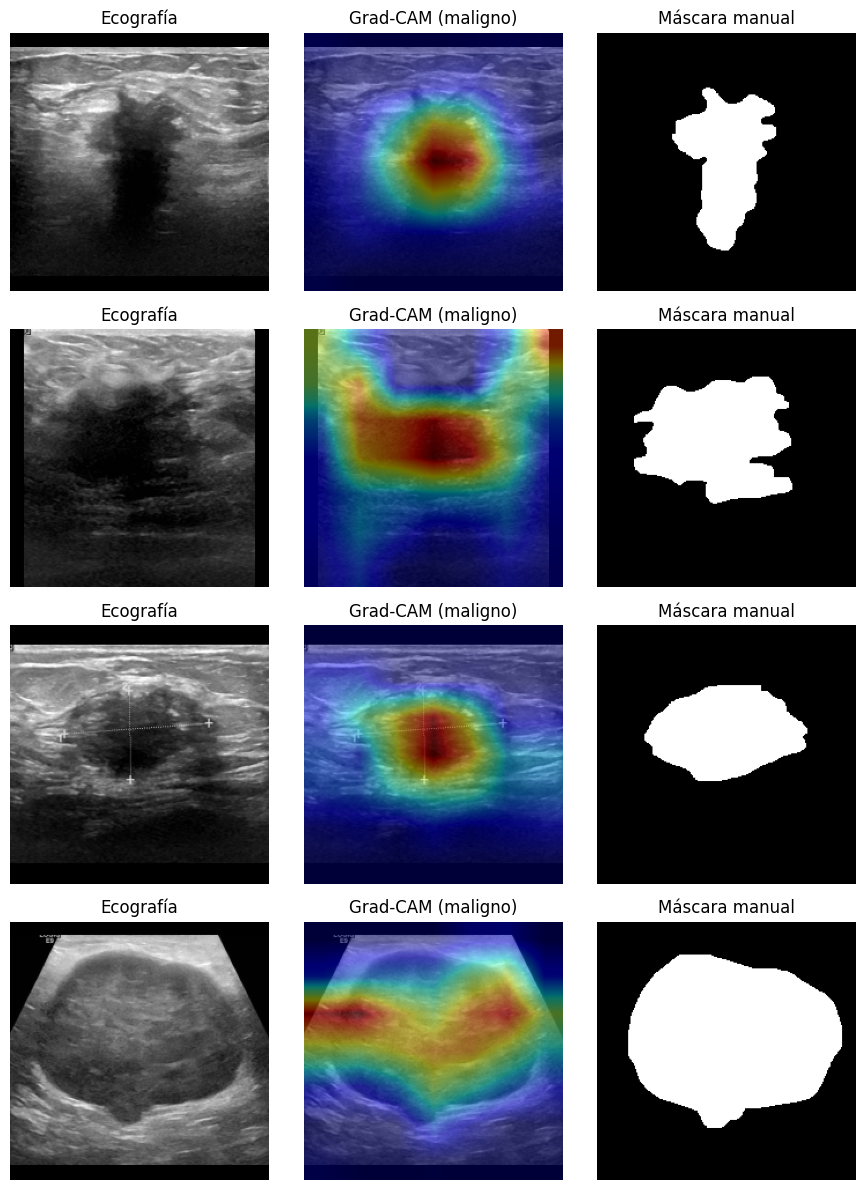

Energía de Grad-CAM dentro de la lesión: 0.53  vs. área de la lesión en la imagen: 0.23 (si es mayor que el área, el modelo mira la lesión más que el azar).


In [14]:
def gradcam(img_gray):
    xin = np.repeat(img_gray[None, ..., None], 3, axis=-1).astype("float32")
    xp = tf.convert_to_tensor(xin[..., ::-1] - MEDIA_BGR)
    with tf.GradientTape() as tape:
        conv = base(xp, training=False); tape.watch(conv)
        score = salida(d1(gap(conv)))[:, MAL]
    gr = tape.gradient(score, conv)
    w = tf.reduce_mean(gr, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0].numpy()
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    return cam / cam.max() if cam.max() > 0 else cam

if elegido == "ResNet50 (TL)":
    ejemplos = [i for i in idx_te if y[i] == MAL and M[i].any()][:4]
    fig, ax = plt.subplots(len(ejemplos), 3, figsize=(9, 3 * len(ejemplos)))
    ax = np.atleast_2d(ax); energia, area = [], []
    for r, i in enumerate(ejemplos):
        cam = gradcam(X[i])
        ax[r, 0].imshow(X[i], cmap="gray"); ax[r, 0].set_title("Ecografía")
        ax[r, 1].imshow(X[i], cmap="gray"); ax[r, 1].imshow(cam, cmap="jet", alpha=.45); ax[r, 1].set_title("Grad-CAM (maligno)")
        ax[r, 2].imshow(M[i], cmap="gray"); ax[r, 2].set_title("Máscara manual")
        for a in ax[r]: a.axis("off")
        energia.append(float(cam[M[i] > 0].sum() / cam.sum())); area.append(float(M[i].mean()))
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gradcam.png", dpi=150); plt.show()
    print(f"Energía de Grad-CAM dentro de la lesión: {np.mean(energia):.2f}  vs. área de la lesión en la imagen: {np.mean(area):.2f}"
          " (si es mayor que el área, el modelo mira la lesión más que el azar).")
else:
    print("El modelo elegido no es la ResNet50: Grad-CAM no se calcula.")

## 7. Valor de negocio (cuantificación)
Escenario ilustrativo por cada **1.000 pacientes con lesión maligna** y por cada **1.000 casos no malignos** (la prevalencia de BUSI no es la de la población; no se extrapolan ahorros monetarios sin datos del centro).

In [15]:
t = rE["m_test"]
cm_ = np.array(t["cm"]); no_mal = cm_.sum() - cm_[MAL].sum(); fp = cm_[:, MAL].sum() - cm_[MAL, MAL]
fpr = fp / no_mal if no_mal else np.nan
det_modelo = t["recall_mal"] * 1000
print(f"Modelo elegido: {elegido}")
print(f"Malignos detectados por cada 1.000: modelo ≈ {det_modelo:.0f} (IC95 {t['ic95_lo'] * 1000:.0f}-{t['ic95_hi'] * 1000:.0f}) vs. literatura ≈ {SENS_LIT * 1000:.0f} "
      f"(IC95 del estimador combinado {SENS_LIT_IC[0] * 1000:.0f}-{SENS_LIT_IC[1] * 1000:.0f}; piso conservador ≈ {SENS_PISO * 1000:.0f})")
print(f"Falsos negativos por cada 1.000 malignos: modelo ≈ {1000 - det_modelo:.0f} vs. literatura ≈ {1000 - SENS_LIT * 1000:.0f} (≈ {1000 - SENS_PISO * 1000:.0f} con el piso)")
print(f"Especificidad del modelo en test: {1 - fpr:.2f} vs. literatura {ESPEC_LIT:.2f} (IC95 {ESPEC_LIT_IC[0]:.2f}-{ESPEC_LIT_IC[1]:.2f}); "
      f"falsos positivos por cada 1.000 no malignos: modelo ≈ {fpr * 1000:.0f} vs. literatura ≈ {(1 - ESPEC_LIT) * 1000:.0f}")
print("Aviso: la referencia es la sensibilidad combinada de la ecografía en 28 estudios (otras poblaciones, lectores y equipos); la comparación es orientativa.")
print(f"Costo: falsos positivos por cada 1.000 casos no malignos ≈ {fpr * 1000:.0f} (revisión adicional del radiólogo)")
print("Ahorro de tiempo de triaje: NO medible con estos datos; requiere piloto en modo sombra en un centro real.")

Modelo elegido: ResNet50 (TL)
Malignos detectados por cada 1.000: modelo ≈ 1000 (IC95 883-1000) vs. literatura ≈ 870 (IC95 del estimador combinado 800-920; piso conservador ≈ 800)
Falsos negativos por cada 1.000 malignos: modelo ≈ 0 vs. literatura ≈ 130 (≈ 200 con el piso)
Especificidad del modelo en test: 0.70 vs. literatura 0.75 (IC95 0.61-0.84); falsos positivos por cada 1.000 no malignos: modelo ≈ 297 vs. literatura ≈ 250
Aviso: la referencia es la sensibilidad combinada de la ecografía en 28 estudios (otras poblaciones, lectores y equipos); la comparación es orientativa.
Costo: falsos positivos por cada 1.000 casos no malignos ≈ 297 (revisión adicional del radiólogo)
Ahorro de tiempo de triaje: NO medible con estos datos; requiere piloto en modo sombra en un centro real.


In [17]:
salida_json = dict(referencia_literatura=dict(fuente="Azarpey, N. (2023). Oncology and Radiotherapy, 17(9), 333-339", sensibilidad=SENS_LIT, sensibilidad_ic95=list(SENS_LIT_IC), especificidad=ESPEC_LIT, especificidad_ic95=list(ESPEC_LIT_IC), piso_conservador=SENS_PISO),
                   config=dict(seed=SEED, img_size=IMG_SIZE, recall_objetivo=RECALL_OBJETIVO, phash_dist=PHASH_DIST, modo_prueba=MODO_PRUEBA),
                   n_total=int(len(df)), n_train=int(len(idx_tr)), n_val=int(len(idx_va)), n_test=int(len(idx_te)),
                   elegido=elegido, cumple_kpi_val=bool(cands),
                   modelos={n: dict(umbral=r["umbral"], cumple_en_val=bool(r["cumple_en_val"]), val=r["m_val"], test=r["m_test"],
                                    test_argmax=r["m_test_argmax"]) for n, r in resultados.items()})
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(salida_json, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Guardado resultados.json y figuras/ — usar estos números en el informe.")

Guardado resultados.json y figuras/ — usar estos números en el informe.


## Anexos de diagnóstico (opcionales; se ejecutan al final y **no** modifican ningún resultado anterior)
- **Anexo A:** sensibilidad de la eliminación de duplicados al umbral de pHash y revisión visual de pares.
- **Anexo B:** Grad-CAM sobre **todos** los malignos de test con máscara (no solo 4) y sobre los falsos positivos.

 umbral_pHash  redundantes  en_conflicto  quedan_total  quedan_normal  quedan_benign  quedan_malignant
            0           39             6           735            124            406               205
            2          111            16           653            102            353               198
            4          143            18           619             94            332               193
            6          164            18           598             91            318               189
            8          169            18           593             91            314               188
(umbral usado en el trabajo: PHASH_DIST = 4 )


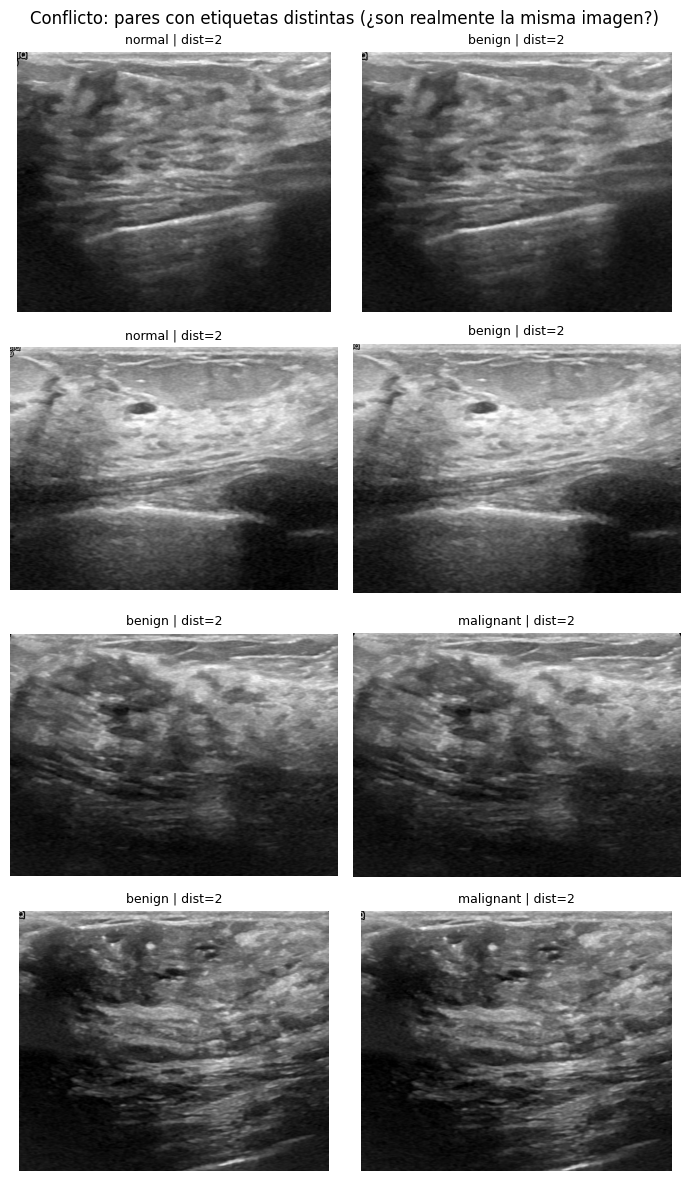

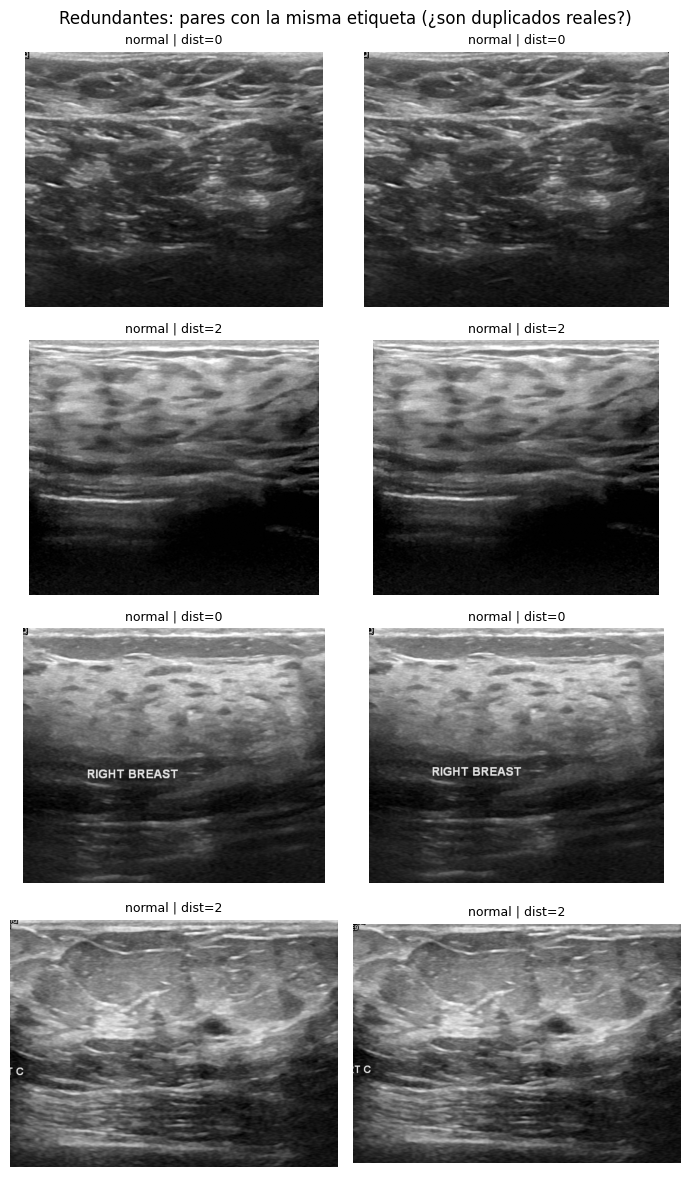

In [16]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

todas = []
for c in CLASSES:
    d = os.path.join(BASE, c)
    for f in sorted(os.listdir(d)):
        if f.lower().endswith(".png") and "_mask" not in f:
            todas.append((os.path.join(d, f), c))
H = [imagehash.phash(Image.open(p).convert("L")) for p, _ in todas]
lab = np.array([c for _, c in todas])
D = np.array([[a - b for b in H] for a in H])

def clusters_a(thr):
    _, comp = connected_components(csr_matrix(D <= thr), directed=False)
    return comp

filas = []
for thr in [0, 2, 4, 6, 8]:
    comp = clusters_a(thr); redundantes = conflicto = 0; quedan = {c: 0 for c in CLASSES}
    for k in np.unique(comp):
        m = np.where(comp == k)[0]
        if len(m) == 1: quedan[lab[m[0]]] += 1
        elif len(set(lab[m])) == 1: redundantes += len(m) - 1; quedan[lab[m[0]]] += 1
        else: conflicto += len(m)
    filas.append(dict(umbral_pHash=thr, redundantes=redundantes, en_conflicto=conflicto,
                      quedan_total=sum(quedan.values()), **{f"quedan_{c}": v for c, v in quedan.items()}))
print(pd.DataFrame(filas).to_string(index=False))
print("(umbral usado en el trabajo: PHASH_DIST =", PHASH_DIST, ")")

def mostrar_pares(pares, titulo, archivo):
    if not pares: print("Sin pares para mostrar:", titulo); return
    fig, ax = plt.subplots(len(pares), 2, figsize=(7, 3 * len(pares)))
    ax = np.atleast_2d(ax)
    for r, (i, j) in enumerate(pares):
        for col, k in enumerate((i, j)):
            ax[r, col].imshow(cv2.imread(todas[k][0], cv2.IMREAD_GRAYSCALE), cmap="gray")
            ax[r, col].set_title(f"{lab[k]} | dist={D[i, j]}", fontsize=9); ax[r, col].axis("off")
    plt.suptitle(titulo); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{archivo}", dpi=120); plt.show()

comp = clusters_a(PHASH_DIST); conf, red = [], []
for k in np.unique(comp):
    m = np.where(comp == k)[0]
    if len(m) > 1:
        if len(set(lab[m])) > 1:
            a = m[0]; b = next(x for x in m if lab[x] != lab[a]); conf.append((a, b))
        elif len(red) < 4: red.append((m[0], m[1]))
mostrar_pares(conf[:4], "Conflicto: pares con etiquetas distintas (¿son realmente la misma imagen?)", "conflicto_pares.png")
mostrar_pares(red[:4], "Redundantes: pares con la misma etiqueta (¿son duplicados reales?)", "redundantes_pares.png")

29 malignos de test con máscara: energía Grad-CAM dentro de la lesión = 0.30 (mediana 0.26) vs. área media de la lesión = 0.14; energía > área en 86% de los casos
Falsos positivos en test: 19; se muestran los 4 con mayor P(maligno)


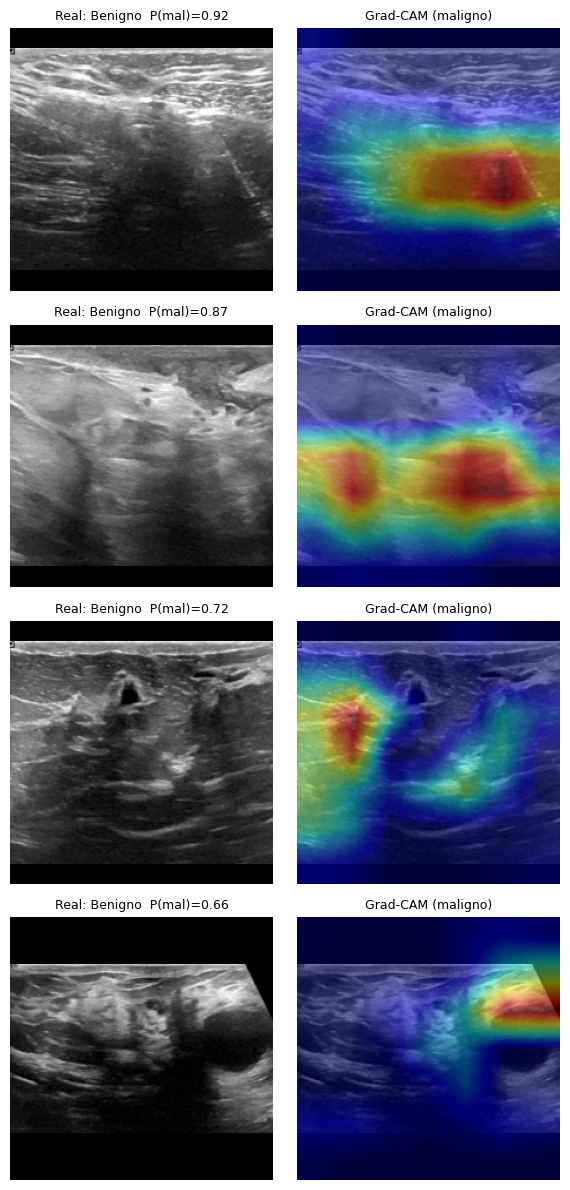

In [18]:
if elegido == "ResNet50 (TL)":
    ids_mal = [i for i in idx_te if y[i] == MAL and M[i].any()]
    en, ar = [], []
    for i in ids_mal:
        cam = gradcam(X[i]); en.append(float(cam[M[i] > 0].sum() / cam.sum())); ar.append(float(M[i].mean()))
    en, ar = np.array(en), np.array(ar)
    print(f"{len(ids_mal)} malignos de test con máscara: energía Grad-CAM dentro de la lesión = {en.mean():.2f} "
          f"(mediana {np.median(en):.2f}) vs. área media de la lesión = {ar.mean():.2f}; "
          f"energía > área en {(en > ar).mean():.0%} de los casos")

    pred_te = pred_umbral(rE["proba_test"], rE["umbral"])
    fps = [(k, idx_te[k]) for k in range(len(idx_te)) if pred_te[k] == MAL and y_te[k] != MAL]
    fps = sorted(fps, key=lambda t: -rE["proba_test"][t[0], MAL])[:4]
    print(f"Falsos positivos en test: {sum((pred_te == MAL) & (y_te != MAL))}; se muestran los 4 con mayor P(maligno)")
    if fps:
        fig, ax = plt.subplots(len(fps), 2, figsize=(6, 3 * len(fps))); ax = np.atleast_2d(ax)
        for r, (k, i) in enumerate(fps):
            cam = gradcam(X[i])
            ax[r, 0].imshow(X[i], cmap="gray"); ax[r, 0].set_title(f"Real: {NOMBRES_ES[CLASSES[y[i]]]}  P(mal)={rE['proba_test'][k, MAL]:.2f}", fontsize=9)
            ax[r, 1].imshow(X[i], cmap="gray"); ax[r, 1].imshow(cam, cmap="jet", alpha=.45); ax[r, 1].set_title("Grad-CAM (maligno)", fontsize=9)
            for a in ax[r]: a.axis("off")
        plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gradcam_falsos_positivos.png", dpi=130); plt.show()
else:
    print("El modelo elegido no es la ResNet50: Anexo B no aplica.")

In [19]:
from google.colab import files
!zip -r figuras.zip figuras
files.download("resultados.json")
files.download("figuras.zip")

  adding: figuras/ (stored 0%)
  adding: figuras/redundantes_pares.png (deflated 1%)
  adding: figuras/evaluacion.png (deflated 11%)
  adding: figuras/gradcam_falsos_positivos.png (deflated 1%)
  adding: figuras/gradcam.png (deflated 1%)
  adding: figuras/matriz_confusion.png (deflated 18%)
  adding: figuras/eda_distribuciones.png (deflated 11%)
  adding: figuras/eda_ejemplos.png (deflated 3%)
  adding: figuras/conflicto_pares.png (deflated 1%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>